# Predicting the final grade of secondary-school students

**Who uses it:** a school counsellor who wants to find students likely to end the year with a low final grade, early enough to offer support.

**Target and task:** regression on G3, the final grade (0 to 20), from the UCI Student Performance dataset (649 students, 30 features).

**Decision supported:** who should receive extra support, and when.

**Cost of mistakes:** overpredicting a struggling student means missing someone who needs help (the worse error). Underpredicting a student who is fine means wasting some support time.

**Design choice (leakage):** G1 and G2 are earlier grades in the same year and are very predictive of G3. I excluded them, so the tool works early, before any grade exists. The price is a lower accuracy, which I report honestly.

In [1]:
from student_grades.config import load_config
from student_grades.data import DatasetLoader

cfg = load_config()
loader = DatasetLoader(cfg)
X, y = loader.load_raw()
print(X.shape)
X.head()

(649, 30)


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,higher,internet,romantic,famrel,freetime,goout,Dalc,Walc,health,absences
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,yes,no,no,4,3,4,1,1,3,4
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,yes,yes,no,5,3,3,1,1,3,2
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,yes,yes,no,4,3,2,2,3,3,6
3,GP,F,15,U,GT3,T,4,2,health,services,...,yes,yes,yes,3,2,2,1,1,5,0
4,GP,F,16,U,GT3,T,3,3,other,other,...,yes,no,no,4,3,2,1,2,5,0


count    649.000000
mean      11.906009
std        3.230656
min        0.000000
25%       10.000000
50%       12.000000
75%       14.000000
max       19.000000
Name: G3, dtype: float64
Students with G3 = 0: 15
Missing values: 0
Duplicate rows: 0


<Axes: >

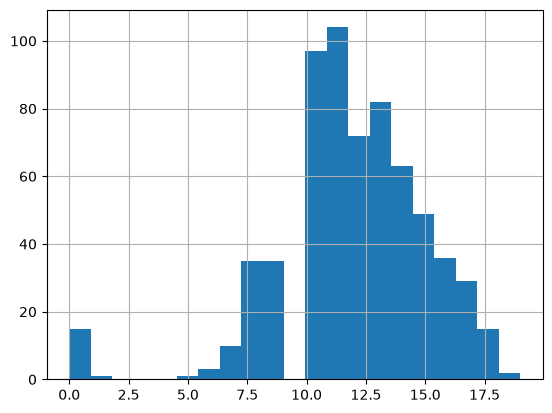

In [2]:
print(y.describe())
print("Students with G3 = 0:", (y == 0).sum())
print("Missing values:", X.isna().sum().sum())
print("Duplicate rows:", X.duplicated().sum())
y.hist(bins=21)

In [3]:
df = X.copy()
df["G3"] = y
print(df[df.G3 == 0][["absences", "failures", "studytime"]].mean())
print(df.select_dtypes("number").corr()["G3"].sort_values())

absences     0.000000
failures     0.800000
studytime    1.466667
dtype: float64
failures     -0.393316
Dalc         -0.204719
Walc         -0.176619
traveltime   -0.127173
freetime     -0.122705
age          -0.106505
health       -0.098851
absences     -0.091379
goout        -0.087641
famrel        0.063361
Fedu          0.211800
Medu          0.240151
studytime     0.249789
G3            1.000000
Name: G3, dtype: float64


In [4]:
from student_grades.models import Trainer

X, y = loader.clean(X, y)
X_train, X_test, y_train, y_test = loader.split(X, y)
print(X_train.shape, X_test.shape)

trainer = Trainer(cfg)
trainer.baselines(X_train, y_train)

(519, 30) (130, 30)


,model,cv_rmse,cv_std
0,dummy_mean,3.186542,0.301774
1,linear_regression,2.761840,0.280722


In [5]:
results = trainer.compare(X_train, y_train)
results

,model,cv_rmse,best_params
0,huber,2.710869,"{'model__alpha': 10.0, 'model__epsilon': 1.35}"
1,ridge,2.713434,{'model__alpha': 100.0}
2,lasso,2.729355,{'model__alpha': 0.05}
3,knn,2.811778,"{'model__n_neighbors': 20, 'model__weights': '..."


In [6]:
cfg = load_config()
trainer = Trainer(cfg)
results = trainer.compare(X_train, y_train)
results

,model,cv_rmse,best_params
0,huber,2.710869,"{'model__alpha': 10.0, 'model__epsilon': 1.35}"
1,ridge,2.713434,{'model__alpha': 100.0}
2,lasso,2.729355,{'model__alpha': 0.05}
3,knn,2.811778,"{'model__n_neighbors': 20, 'model__weights': '..."


In [7]:
import numpy as np
from sklearn.model_selection import cross_val_predict

print("Chosen:", trainer.best_name, trainer.best_model.named_steps["model"])
oof = cross_val_predict(trainer.best_model, X_train, y_train, cv=5)
res = y_train - oof
print("RMSE:", np.sqrt((res**2).mean()), " MAE:", res.abs().mean())
share = (res[y_train == 0] ** 2).sum() / (res**2).sum()
print("Share of squared error from G3=0 students:", share)
print("RMSE without G3=0 students:", np.sqrt((res[y_train > 0] ** 2).mean()))

Chosen: huber HuberRegressor(alpha=10.0, max_iter=1000)
RMSE: 2.7200426291549906  MAE: 1.937930167389807
Share of squared error from G3=0 students: 0.3277138218551549
RMSE without G3=0 students: 2.254263215975627


In [8]:
print(trainer.baselines(X_train, y_train).to_string())
print(results.to_string())

               model   cv_rmse    cv_std
0         dummy_mean  3.186542  0.301774
1  linear_regression  2.761840  0.280722
   model   cv_rmse                                               best_params
0  huber  2.710869            {'model__alpha': 10.0, 'model__epsilon': 1.35}
1  ridge  2.713434                                   {'model__alpha': 100.0}
2  lasso  2.729355                                    {'model__alpha': 0.05}
3    knn  2.811778  {'model__n_neighbors': 20, 'model__weights': 'distance'}


## Model comparison

Four models were tuned with `GridSearchCV` on the training set only, all under the same repeated 5-fold cross-validation (CV RMSE, in grade points, lower is better).

| Model | Tuned hyperparameter(s) | Best value | CV RMSE |
|---|---|---|---|
| Dummy (average grade) | none | none | 3.19 |
| Linear regression | none | none | 2.76 |
| Huber | alpha, epsilon | 10, 1.35 | 2.71 |
| Ridge | alpha | 100 | 2.71 |
| Lasso | alpha | 0.05 | 2.73 |
| k-NN | k, weights | 20, distance | 2.81 |

- **Ridge** shrinks the coefficients to reduce overfitting. **Lasso** shrinks some of them to exactly zero. **k-NN** predicts the average grade of the k most similar students. **Huber** is a linear model whose loss grows only linearly for large errors, so a few outliers pull it less.
- The Ridge grid was widened (up to alpha = 1000) to check that the best value (100) is inside the grid and not at its edge.
- Huber, Ridge and Lasso differ by less than 0.02, far below the fold-to-fold spread (about 0.3), so they are effectively tied. k-NN is clearly weaker.
- **Chosen model: Huber.** It ties for the best score, and the squared-error loss of the other models is sensitive to the 15 students with G3 = 0, which account for about 31% of Ridge's squared error while being 2% of the students.

## Metric and loss

**Metric.** RMSE and MAE, both in grade points. RMSE punishes large errors more, which fits the cost of missing a struggling student, and MAE is easier to explain to a counsellor ("on average the prediction is off by about 2 points"). The out-of-fold predictions of the chosen model on the training set give an RMSE of 2.72 and an MAE of 1.94.

**Loss.** Ridge and Lasso minimise squared error (MSE). The 15 students with G3 = 0 produce about a third of the total squared error although they are 2% of the students, so squared error lets them pull the fit. Huber loss is quadratic for small errors and linear for large ones, which limits their influence. That is why Huber was added as a fourth model and chosen.

**Evaluation protocol.** Every choice (model, hyperparameters, loss) was made with cross-validation on the training set. The test set is used once, in the next step, and nothing is changed afterwards.

{'rmse': 2.8514344521903765, 'mae': 2.0344940522475543}


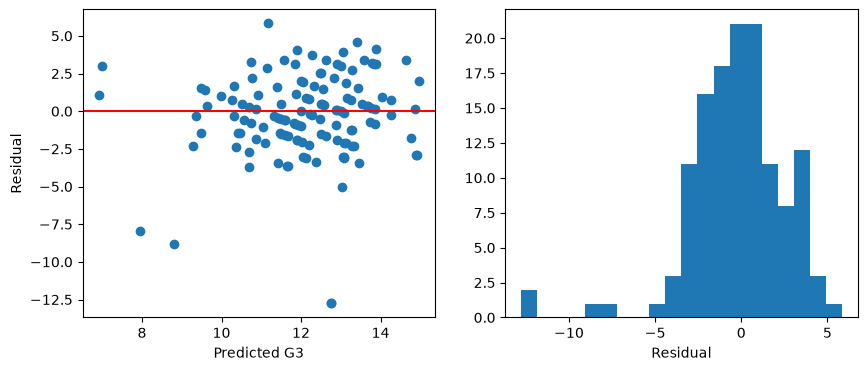

In [9]:
import matplotlib.pyplot as plt

print(trainer.test_score(X_test, y_test))
pred = trainer.predict(X_test)
resid = y_test - pred

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].scatter(pred, resid)
ax[0].axhline(0, color="red")
ax[0].set_xlabel("Predicted G3")
ax[0].set_ylabel("Residual")
ax[1].hist(resid, bins=20)
ax[1].set_xlabel("Residual")
plt.show()

## Test result (used once)

The chosen model (Huber, alpha = 10, epsilon = 1.35) was refitted on the whole training set and scored once on the 130 held-out students:

| Metric | Cross-validation (train) | Test |
|---|---|---|
| RMSE | 2.72 | **2.85** |
| MAE | 1.94 | **2.03** |

- The test error is slightly higher than the CV error, but the gap is much smaller than the fold-to-fold spread (about 0.3). The model generalises about as well as expected, with no sign of overfitting. Compared with the Dummy baseline (CV RMSE 3.19), it reduces the error by roughly 10%.
- **Residual plot.** Most residuals lie between -4 and +4 around zero, with no clear curve. Three points are far below the line (about -8, -9 and -12): these are overpredictions, most likely students with G3 = 0 whom the model expected to pass.
- **Predictions only range from about 7 to 15.** The model stays close to the average and cannot identify extreme cases.
- Nothing was changed after seeing the test score.

In [10]:
import pandas as pd

model = trainer.best_model
names = model.named_steps["prep"].get_feature_names_out()
coefs = pd.Series(model.named_steps["model"].coef_, index=names)
print(coefs.reindex(coefs.abs().sort_values(ascending=False).index).head(12))

num__failures            -0.749718
cat__schoolsup_yes       -0.569080
cat__schoolsup_no         0.568446
cat__higher_no           -0.551637
cat__higher_yes           0.551003
cat__Fjob_services       -0.471856
cat__Fjob_teacher         0.461821
cat__school_MS           -0.434478
cat__school_GP            0.433843
cat__reason_reputation    0.309758
num__studytime            0.307553
num__absences            -0.292085
dtype: float64


## Interpretation

**Most important features** (standardised coefficients of the Huber model; one unit = one standard deviation for numeric features, and yes/no pairs are one binary feature):
- **Past failures (-0.75):** the strongest effect. Each extra standard deviation of failures lowers the predicted grade by about 0.75 points.
- **Wanting higher education (+0.55 for yes):** students who want to continue to university are predicted about 1.1 points higher than those who do not.
- **Extra school support (-0.57 for yes):** students who receive it are predicted lower. This is probably because weaker students are the ones who get support, not because support lowers grades.
- **Study time (+0.31)** raises the prediction and **absences (-0.29)** lower it.
- **School (GP higher than MS)** and **father's job (teacher higher than services)** also matter.

These are associations, not causes. The coefficients are also shrunk by the regularisation.

## Two limits of the model

1. **It cannot find the students who matter most.** Without G1 and G2, predictions stay between about 7 and 15, and the 15 students with G3 = 0 (dropout or skipped exam) are not detected: they produce the largest errors, about a third of the squared error.
2. **Small and narrow data.** Only 649 students from two Portuguese schools, so the error is large (about 2 grade points on average) and the model may not transfer to other schools or countries. Differences between the top models are within the noise of cross-validation.

## Risks of using it on real people

A wrong prediction can label a student unfairly: a low prediction may reduce expectations or attention, and a high one may hide a student who needs help. Several features act as proxies for social background (school, father's job, wish for higher education), so the model could reproduce existing inequalities and treat students differently because of their family rather than their effort. The data also contains sensitive personal information (family situation, alcohol use, health, romantic relationship), which raises privacy concerns about storage, access and consent. The tool should only support a human decision by the counsellor and never replace it, and students should not be ranked or sanctioned from its output alone.

## Data exploration

- **649 students, 30 features**, no missing values and no duplicate rows.
- **Special code:** 15 students (about 2%) have G3 = 0. This is probably a code for students who dropped out or skipped the final exam, not a real score. Their average number of absences is 0, which suggests their absences were never recorded. I **kept them** because a counsellor would meet such students in real life. Removing them would make the tool look better than it is.
- **Weak to moderate links with G3:** past failures (-0.39), alcohol use (-0.20 and -0.18), mother's education (+0.24), father's education (+0.21), study time (+0.25).
- **Leakage check:** G1 and G2 are excluded (see above). All the other features are known before the final exam.
- **Split:** done once, 80% train (519) and 20% test (130), stratified on target quartiles. The test set is not used until the final evaluation.